# Part II - Practical Work

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

## Grundeinstellungen

In [2]:
SEED = 42
N_TRAIN = 10_000
N_OBSERVATIONS = 10
BATCH_SIZE = 128
EPOCHS = 100
LEARNING_RATE = 1e-3

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Verwendetes Gerät:", device)

Verwendetes Gerät: cuda


Disclaimer: Dieses Notebook wurde mithilfe von ChatGPT erstellt.

### a )

generate 10.000 labbeld training examples from Task 2. Train and compare networks with architectures

10 → 16 → 1,
10 → 64 → 1,
10 → 32 → 32 → 1,
10 → 64 → 64 → 32 → 1

Use the notebook’s common training settings and sorted input vectors

Gelabelte Trainingsdaten aus Aufgabe 2 erzeugen:

In [3]:
rng = np.random.default_rng(SEED)

# Für jedes Beispiel einen eigenen Endpunkt ziehen.
# Shape: (10_000, 1)
L_train = rng.uniform(1.0, 5.0, size=(N_TRAIN, 1))

# Pro Endpunkt zehn bedingt unabhängige Beobachtungen aus [0, L].
# Shape: (10_000, 10)
X_train = rng.uniform(
    0.0, 1.0, size=(N_TRAIN, N_OBSERVATIONS)
) * L_train

# Innerhalb jedes Beispiels sortieren.
X_train = np.sort(X_train, axis=1).astype(np.float32)
y_train = L_train.astype(np.float32)

X_train_tensor = torch.from_numpy(X_train)
y_train_tensor = torch.from_numpy(y_train)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

print("Features:", X_train.shape)
print("Labels:", y_train.shape)

Features: (10000, 10)
Labels: (10000, 1)


Die vier vorgegebenen Netzwerkarchitekturen aufbauen:

In [4]:
architectures = {
    "10 → 16 → 1": [10, 16, 1],
    "10 → 64 → 1": [10, 64, 1],
    "10 → 32 → 32 → 1": [10, 32, 32, 1],
    "10 → 64 → 64 → 32 → 1": [10, 64, 64, 32, 1],
}

In [5]:
def build_network(widths):
    layers = []

    for i in range(len(widths) - 1):
        layers.append(nn.Linear(widths[i], widths[i + 1]))

        # ReLU nur nach den versteckten Schichten.
        # Die Ausgabeschicht liefert einen numerischen Wert.
        if i < len(widths) - 2:
            layers.append(nn.ReLU())

    return nn.Sequential(*layers)

Alle Netze auf denselben Trainingsdaten trainieren

In [6]:
models = {}
histories = {}
results = []

loss_function = nn.MSELoss()

In [7]:
for name, widths in architectures.items():
    # Reproduzierbare Initialisierung je Architektur.
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = build_network(widths).to(device)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE
    )

    # Gleiche Reihenfolge der Trainingsbatches für jedes Netz.
    shuffle_generator = torch.Generator().manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=shuffle_generator,
    )

    # Für die Bewertung der fertigen Regel nach jeder Epoche.
    evaluation_loader = DataLoader(
        train_dataset,
        batch_size=1024,
        shuffle=False,
    )

    history = []

    for epoch in range(EPOCHS):
        model.train()

        for features, labels in train_loader:
            features = features.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            predictions = model(features)
            loss = loss_function(predictions, labels)
            loss.backward()
            optimizer.step()

        # Empirisches Risiko des aktuellen Modells auf ALLEN
        # Trainingsbeispielen; Modell dabei nicht verändern.
        model.eval()
        squared_error_sum = 0.0

        with torch.no_grad():
            for features, labels in evaluation_loader:
                features = features.to(device)
                labels = labels.to(device)

                predictions = model(features)
                squared_error_sum += (
                    (predictions - labels).square().sum().item()
                )

        train_mse = squared_error_sum / N_TRAIN
        history.append(train_mse)

        if (epoch + 1) % 20 == 0:
            print(
                f"{name} | Epoche {epoch + 1:3d}/{EPOCHS} "
                f"| Trainings-MSE: {train_mse:.6f}"
            )

    # Für Teil II(b) und II(c) aufbewahren.
    models[name] = model
    histories[name] = history

    results.append({
        "Architektur": name,
        "Parameter": sum(p.numel() for p in model.parameters()),
        "Trainings-MSE": history[-1],
    })

10 → 16 → 1 | Epoche  20/100 | Trainings-MSE: 0.131962
10 → 16 → 1 | Epoche  40/100 | Trainings-MSE: 0.082373
10 → 16 → 1 | Epoche  60/100 | Trainings-MSE: 0.083409
10 → 16 → 1 | Epoche  80/100 | Trainings-MSE: 0.085050
10 → 16 → 1 | Epoche 100/100 | Trainings-MSE: 0.081642
10 → 64 → 1 | Epoche  20/100 | Trainings-MSE: 0.082345
10 → 64 → 1 | Epoche  40/100 | Trainings-MSE: 0.079652
10 → 64 → 1 | Epoche  60/100 | Trainings-MSE: 0.081138
10 → 64 → 1 | Epoche  80/100 | Trainings-MSE: 0.086154
10 → 64 → 1 | Epoche 100/100 | Trainings-MSE: 0.078706
10 → 32 → 32 → 1 | Epoche  20/100 | Trainings-MSE: 0.082477
10 → 32 → 32 → 1 | Epoche  40/100 | Trainings-MSE: 0.080908
10 → 32 → 32 → 1 | Epoche  60/100 | Trainings-MSE: 0.080470
10 → 32 → 32 → 1 | Epoche  80/100 | Trainings-MSE: 0.082427
10 → 32 → 32 → 1 | Epoche 100/100 | Trainings-MSE: 0.079961
10 → 64 → 64 → 32 → 1 | Epoche  20/100 | Trainings-MSE: 0.079675
10 → 64 → 64 → 32 → 1 | Epoche  40/100 | Trainings-MSE: 0.085320
10 → 64 → 64 → 32 → 

Vergleich auf den Trainingsdaten

,Architektur,Parameter,Trainings-MSE
0,10 → 16 → 1,193,0.081642
1,10 → 64 → 1,769,0.078706
2,10 → 32 → 32 → 1,1441,0.079961
3,10 → 64 → 64 → 32 → 1,6977,0.077674


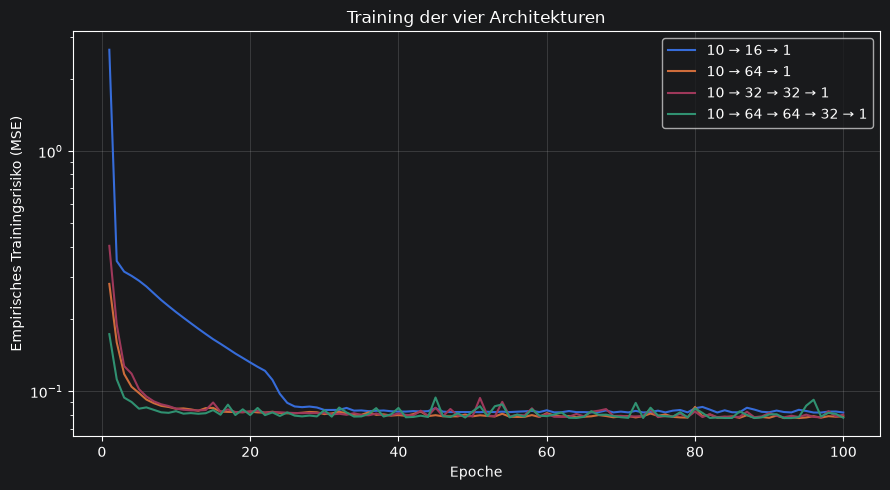

In [8]:
results_a = pd.DataFrame(results)
display(results_a.round(6))

plt.figure(figsize=(9, 5))

for name, history in histories.items():
    plt.plot(range(1, EPOCHS + 1), history, label=name)

plt.xlabel("Epoche")
plt.ylabel("Empirisches Trainingsrisiko (MSE)")
plt.title("Training der vier Architekturen")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## b)

Compare the training and test errors of the four fitted hypotheses and h1, h2, h3, using 20,000
common, independent test examples. Present a table and a plot. Compare with your theoretical
results.

Neue Unabhängige Testbeispiele erzeugen:

In [9]:
N_TEST = 20_000
test_rng = np.random.default_rng(SEED + 1)

L_test = test_rng.uniform(1.0, 5.0, size=(N_TEST, 1))

X_test = test_rng.uniform(
    0.0, 1.0, size=(N_TEST, N_OBSERVATIONS)
) * L_test

X_test = np.sort(X_test, axis=1).astype(np.float32)
y_test = L_test.astype(np.float32)

Implementierung der drei Hypothesen aus Part 1

In [10]:
def h1(X):
    return 2.0 * np.mean(X, axis=1, keepdims=True)


def h2(X):
    return np.max(X, axis=1, keepdims=True)


def h3(X):
    N = X.shape[1]
    return ((N + 1) / N) * np.max(X, axis=1, keepdims=True)

In [12]:
hypothetical_rules = {
    "h1: 2 × Mittelwert": h1,
    "h2: Maximum": h2,
    "h3: korrigiertes Maximum": h3,
}

# Ergebnisse aus Teil I, Aufgabe 2(b), für N = 10.
theoretical_risks = {
    "h1: 2 × Mittelwert": 31 / 90,
    "h2: Maximum": 31 / 198,
    "h3: korrigiertes Maximum": 31 / 360,
}

In [13]:
def mse(predictions, targets):
    # float64 für die Berechnung des Durchschnitts.
    errors = (
        np.asarray(predictions, dtype=np.float64)
        - np.asarray(targets, dtype=np.float64)
    )
    return np.mean(errors**2)

In [14]:
def predict_network(model, X, batch_size=1024):
    model.eval()
    model_device = next(model.parameters()).device

    loader = DataLoader(
        TensorDataset(torch.from_numpy(X)),
        batch_size=batch_size,
        shuffle=False,
    )

    predictions = []

    with torch.no_grad():
        for (features,) in loader:
            batch_predictions = model(features.to(model_device))
            predictions.append(batch_predictions.cpu().numpy())

    return np.concatenate(predictions, axis=0)

Trainings- und Testfehler aller sieben Regeln

In [15]:
rows = []

for name, model in models.items():
    train_predictions = predict_network(model, X_train)
    test_predictions = predict_network(model, X_test)

    rows.append({
        "Hypothese": name,
        "Trainings-MSE": mse(train_predictions, y_train),
        "Test-MSE": mse(test_predictions, y_test),
        "Theoretisches Risiko": np.nan,
    })

for name, rule in hypothetical_rules.items():
    rows.append({
        "Hypothese": name,
        "Trainings-MSE": mse(rule(X_train), y_train),
        "Test-MSE": mse(rule(X_test), y_test),
        "Theoretisches Risiko": theoretical_risks[name],
    })

results_b = pd.DataFrame(rows)

display(
    results_b.style.format({
        "Trainings-MSE": "{:.6f}",
        "Test-MSE": "{:.6f}",
        "Theoretisches Risiko": "{:.6f}",
    }, na_rep="—")
)

,Hypothese,Trainings-MSE,Test-MSE,Theoretisches Risiko
0,10 → 16 → 1,0.081642,0.081180,—
1,10 → 64 → 1,0.078706,0.078868,—
2,10 → 32 → 32 → 1,0.079961,0.079223,—
3,10 → 64 → 64 → 32 → 1,0.077674,0.077759,—
4,h1: 2 × Mittelwert,0.344648,0.346610,0.344444
5,h2: Maximum,0.156561,0.156093,0.156566
6,h3: korrigiertes Maximum,0.087066,0.086706,0.086111


Gemeinsamer Vergleich als Plot

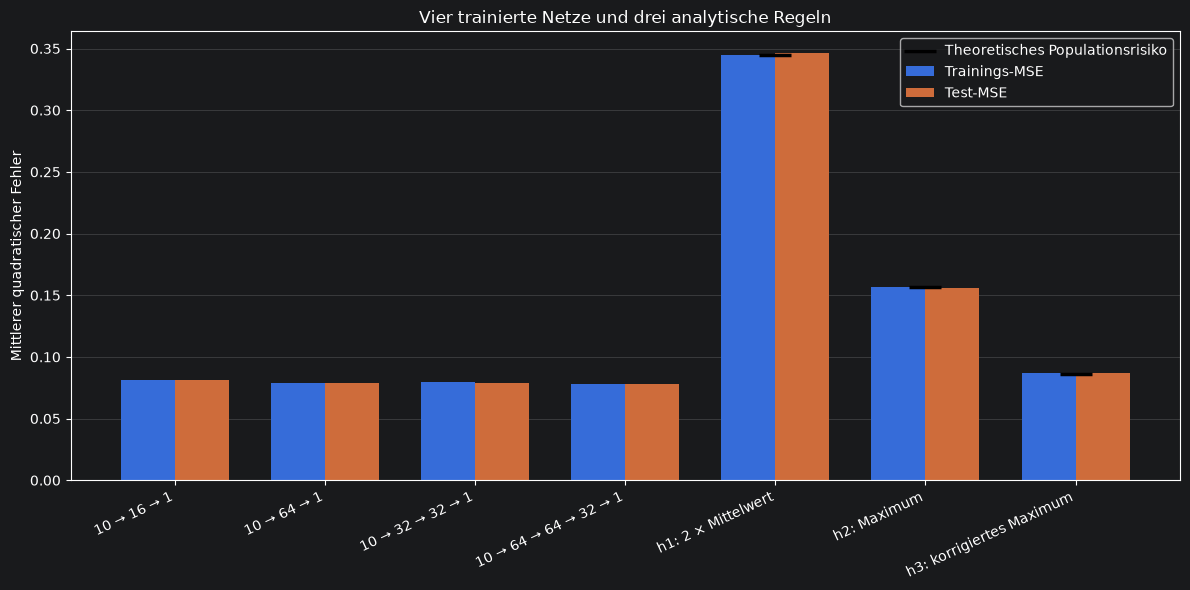

In [16]:
positions = np.arange(len(results_b))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    positions - bar_width / 2,
    results_b["Trainings-MSE"],
    width=bar_width,
    label="Trainings-MSE",
)

ax.bar(
    positions + bar_width / 2,
    results_b["Test-MSE"],
    width=bar_width,
    label="Test-MSE",
)

# Theoretische Risiken nur dort anzeigen, wo sie bekannt sind.
has_theory = results_b["Theoretisches Risiko"].notna().to_numpy()

ax.scatter(
    positions[has_theory],
    results_b.loc[has_theory, "Theoretisches Risiko"],
    color="black",
    marker="_",
    s=500,
    linewidths=2.5,
    label="Theoretisches Populationsrisiko",
    zorder=5,
)

ax.set_xticks(positions)
ax.set_xticklabels(
    results_b["Hypothese"],
    rotation=25,
    ha="right",
)
ax.set_ylabel("Mittlerer quadratischer Fehler")
ax.set_title("Vier trainierte Netze und drei analytische Regeln")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend()

plt.tight_layout()
plt.show()

-> kommt gut mit den errechneten Werten aus Theorie hin

Numerischer Abgleich mit der Theorie

In [17]:
theory_comparison = results_b.loc[
    has_theory,
    ["Hypothese", "Test-MSE", "Theoretisches Risiko"],
].copy()

theory_comparison["Test minus Theorie"] = (
    theory_comparison["Test-MSE"]
    - theory_comparison["Theoretisches Risiko"]
)

display(
    theory_comparison.style.format({
        "Test-MSE": "{:.6f}",
        "Theoretisches Risiko": "{:.6f}",
        "Test minus Theorie": "{:+.6f}",
    })
)

,Hypothese,Test-MSE,Theoretisches Risiko,Test minus Theorie
4,h1: 2 × Mittelwert,0.346610,0.344444,+0.002166
5,h2: Maximum,0.156093,0.156566,-0.000473
6,h3: korrigiertes Maximum,0.086706,0.086111,+0.000595


## c)

For each fixed L ∈ {0.5, 1, 2, 3, 4, 5, 6, 8}, evaluate all seven hypotheses on 5,000 fresh feature
vectors. Plot the empirical errors against L. Keep the trained networks unchanged. Discuss the
results inside and outside [1, 5].

weitere Grundeinstellungen

In [18]:
L_values = [0.5, 1, 2, 3, 4, 5, 6, 8]
N_EVAL = 5_000

evaluation_rng = np.random.default_rng(SEED + 2)
rows_c = []


Für jedes feste L neue Daten erzeugen und Regeln bewerten

In [19]:
for L in L_values:
    X_fixed = evaluation_rng.uniform(
        0.0, L, size=(N_EVAL, N_OBSERVATIONS)
    )

    # Dieselbe Eingabeaufbereitung wie beim Training.
    X_fixed = np.sort(X_fixed, axis=1).astype(np.float32)

    # Innerhalb dieses Experiments ist das Label immer L.
    y_fixed = np.full((N_EVAL, 1), L, dtype=np.float32)

    # Netze nur auswerten, nicht erneut trainieren.
    for name, model in models.items():
        predictions = predict_network(model, X_fixed)

        rows_c.append({
            "L": L,
            "Hypothese": name,
            "Empirischer MSE": mse(predictions, y_fixed),
        })

    # Analytische Regeln auf denselben Eingabevektoren auswerten.
    for name, rule in analytic_rules.items():
        predictions = rule(X_fixed)

        rows_c.append({
            "L": L,
            "Hypothese": name,
            "Empirischer MSE": mse(predictions, y_fixed),
        })

results_c = pd.DataFrame(rows_c)

Fehler pro Regel und festem L

In [20]:
rule_order = list(models.keys()) + list(analytic_rules.keys())

table_c = results_c.pivot(
    index="L",
    columns="Hypothese",
    values="Empirischer MSE",
).reindex(columns=rule_order)

display(table_c.style.format("{:.6f}"))

Hypothese,10 → 16 → 1,10 → 64 → 1,10 → 32 → 32 → 1,10 → 64 → 64 → 32 → 1,h1: 2 × Mittelwert,h2: Maximum,h3: korrigiertes Maximum
L,,,,,,,
0.500000,0.019932,0.302485,0.103936,0.541303,0.008228,0.003665,0.002000
1.000000,0.022118,0.012055,0.012218,0.018013,0.033124,0.015050,0.008339
2.000000,0.032933,0.037493,0.034075,0.039817,0.133281,0.060121,0.033220
3.000000,0.064087,0.072208,0.070973,0.083285,0.301905,0.132636,0.073036
4.000000,0.116934,0.099354,0.101281,0.093547,0.534261,0.238131,0.127955
5.000000,0.200433,0.218677,0.225262,0.186721,0.808669,0.374228,0.210692
6.000000,0.284756,0.418210,0.447153,0.363630,1.170494,0.517953,0.285397
8.000000,0.570608,1.170359,1.289121,1.074195,2.097421,0.963877,0.526679


Empirische Fehler gegen L plotten

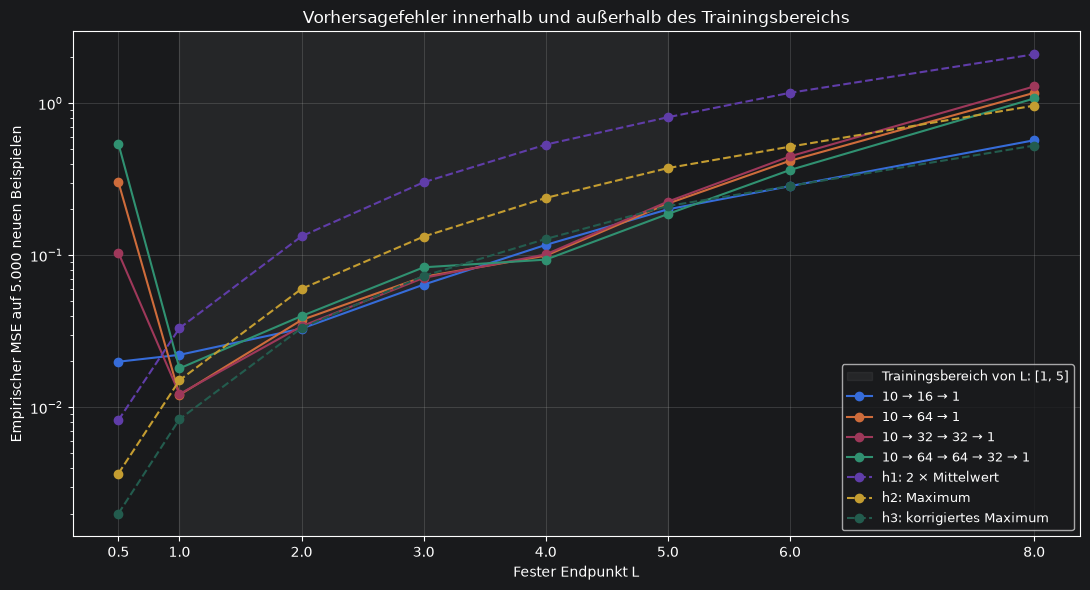

In [21]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.axvspan(
    1, 5,
    color="gray",
    alpha=0.12,
    label="Trainingsbereich von L: [1, 5]",
)

for name in rule_order:
    values = table_c[name]

    ax.plot(
        table_c.index,
        values,
        marker="o",
        linestyle="--" if name in analytic_rules else "-",
        label=name,
    )

ax.set_xlabel("Fester Endpunkt L")
ax.set_ylabel("Empirischer MSE auf 5.000 neuen Beispielen")
ax.set_title("Vorhersagefehler innerhalb und außerhalb des Trainingsbereichs")
ax.set_xticks(L_values)
ax.set_yscale("log")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

Ergänzend: Kontrolle mit der Theorie aus Aufgabe 1(b)

In [22]:
N = N_OBSERVATIONS

fixed_L_risks = {
    "h1: 2 × Mittelwert": lambda L: L**2 / (3 * N),
    "h2: Maximum": lambda L: 2 * L**2 / ((N + 1) * (N + 2)),
    "h3: korrigiertes Maximum": lambda L: L**2 / (N * (N + 2)),
}

theory_rows = []

for L in L_values:
    for name, risk_formula in fixed_L_risks.items():
        theoretical_risk = risk_formula(L)
        empirical_risk = table_c.loc[L, name]

        theory_rows.append({
            "L": L,
            "Hypothese": name,
            "Empirischer MSE": empirical_risk,
            "Theoretisches Risiko": theoretical_risk,
            "Differenz": empirical_risk - theoretical_risk,
        })

comparison_c = pd.DataFrame(theory_rows)

display(
    comparison_c.style.format({
        "L": "{:g}",
        "Empirischer MSE": "{:.6f}",
        "Theoretisches Risiko": "{:.6f}",
        "Differenz": "{:+.6f}",
    })
)

,L,Hypothese,Empirischer MSE,Theoretisches Risiko,Differenz
0,0.5,h1: 2 × Mittelwert,0.008228,0.008333,-0.000105
1,0.5,h2: Maximum,0.003665,0.003788,-0.000123
2,0.5,h3: korrigiertes Maximum,0.002000,0.002083,-0.000084
3,1,h1: 2 × Mittelwert,0.033124,0.033333,-0.000209
4,1,h2: Maximum,0.015050,0.015152,-0.000101
5,1,h3: korrigiertes Maximum,0.008339,0.008333,+0.000005
6,2,h1: 2 × Mittelwert,0.133281,0.133333,-0.000052
7,2,h2: Maximum,0.060121,0.060606,-0.000485
8,2,h3: korrigiertes Maximum,0.033220,0.033333,-0.000113
9,3,h1: 2 × Mittelwert,0.301905,0.300000,+0.001905


**Vergleich mit der Theorie**

Die empirischen MSE-Werte aus jeweils 5.000 Beispielen liegen für alle untersuchten Endpunkte nahe an den theoretischen Risiken
$$
R_L(h_1)=\frac{L^2}{30},\qquad
R_L(h_2)=\frac{L^2}{66},\qquad
R_L(h_3)=\frac{L^2}{120}.
$$

Die relativen Abweichungen betragen durchgehend weniger als etwa $5{,}1\%$. Die verbleibenden Unterschiede sind mit zufälligen Schwankungen einer endlichen Teststichprobe vereinbar. Ein empirischer Fehler unterhalb des theoretischen Risikos ist dabei kein Widerspruch: Das theoretische Risiko ist ein Erwartungswert, keine untere Schranke für jeden gemessenen Durchschnitt.

**Vergleich der drei Hypothesen**

Für sämtliche betrachteten Werte von $L$ bestätigt sich die theoretische Rangfolge:
$$
\widehat R(h_3)<\widehat R(h_2)<\widehat R(h_1).
$$

Das korrigierte Maximum $h_3$ erzielt somit unter diesen drei Regeln stets den kleinsten gemessenen Fehler.

Sowohl $h_1$ als auch $h_3$ sind erwartungstreu, dennoch besitzt $h_3$ die kleinere Varianz und damit das kleinere quadratische Risiko. Das unkorrigierte Maximum $h_2$ unterschätzt $L$ im Mittel, schneidet aber trotzdem besser ab als $h_1$. **Erwartungstreue allein entscheidet also nicht über die Vorhersagequalität.**

**Verhalten innerhalb und außerhalb von $[1,5]$**

Auch für $L=0{,}5$, $6$ und $8$ stimmen die empirischen Ergebnisse gut mit den theoretischen Werten überein. Die analytischen Regeln wurden nicht an den Bereich $[1,5]$ angepasst; ihre Risikoformeln gelten für jedes $L>0$.

Der Fehler steigt ungefähr quadratisch mit $L$. Das entspricht der Theorie und ist kein Hinweis auf ein zusätzliches Versagen außerhalb des Trainingsbereichs. Nach Division durch $L^2$ bleiben die theoretischen Risiken konstant:
$$
\frac{R_L(h_1)}{L^2}=\frac1{30},\qquad
\frac{R_L(h_2)}{L^2}=\frac1{66},\qquad
\frac{R_L(h_3)}{L^2}=\frac1{120}.
$$

### Vergleich der neuronalen Netze innerhalb des Trainingsbereichs

Innerhalb von $[1,5]$ erzielen die neuronalen Netze überwiegend Fehler in einer ähnlichen Größenordnung wie das korrigierte Maximum $h_3$. Alle vier Netze schneiden an den untersuchten Punkten besser ab als $h_1$.

Keine Architektur ist bei allen Endpunkten am besten:

- Bei $L=1$ hat $h_3$ den kleinsten empirischen Fehler.
- Bei $L=2$ liegt das Netz $10 \to 16 \to 1$ knapp vor $h_3$. Der Unterschied ist sehr klein und sollte ohne weitere Wiederholungen nicht überinterpretiert werden.
- Bei $L=3$ erzielt ebenfalls das Netz $10 \to 16 \to 1$ den kleinsten Fehler.
- Bei $L=4$ und $L=5$ schneidet das tiefste Netz $10 \to 64 \to 64 \to 32 \to 1$ am besten ab.

Dass Netze teilweise besser als $h_3$ abschneiden, widerspricht der Theorie nicht: $h_3$ ist nur die beste der drei untersuchten analytischen Regeln. Außerdem können die Netze die im Training vorgegebene Verteilung $L \sim \operatorname{Unif}[1,5]$ berücksichtigen, während die analytischen Regeln nicht speziell auf diesen Bereich abgestimmt sind.

### Verhalten außerhalb des Trainingsbereichs

Bei $L=0{,}5$ schneiden alle Netze deutlich schlechter ab als die analytischen Regeln. Das korrigierte Maximum erreicht einen MSE von etwa $0{,}0020$, während die Netzfehler zwischen $0{,}0199$ und $0{,}5413$ liegen. Besonders das tiefste Netz zeigt hier eine starke Verschlechterung.

Bei $L=6$ liegt das kleinste Netz nahezu gleichauf mit $h_3$. Die übrigen Netze haben höhere Fehler. Bei $L=8$ erzielt $h_3$ den kleinsten Fehler aller sieben Regeln. Das kleinste Netz bleibt mit einem MSE von etwa $0{,}571$ vergleichsweise nahe daran; die anderen Netze liegen zwischen etwa $1{,}074$ und $1{,}289$ und schneiden damit sogar schlechter als das unkorrigierte Maximum $h_2$ ab.

Der bloße Anstieg des MSE bei größerem $L$ ist allerdings noch kein Beleg für schlechte Extrapolation, da bereits die theoretischen Risiken der analytischen Regeln proportional zu $L^2$ wachsen. Aussagekräftiger ist der Vergleich mit diesen Regeln beim gleichen Endpunkt. Dieser zeigt insbesondere für die größeren Netze außerhalb des Trainingsbereichs zusätzliche Fehler.

### Fazit

Die neuronalen Netze können innerhalb des Trainingsbereichs mit den analytischen Regeln konkurrieren und diese an einzelnen Endpunkten übertreffen. Außerhalb dieses Bereichs ist ihre Leistung jedoch weniger zuverlässig. Unter den trainierten Netzen zeigt die kleinste Architektur in diesem Versuch die robusteste Extrapolation.

Mehr Schichten oder Parameter führen somit nicht automatisch zu besseren Vorhersagen. Die Ergebnisse beziehen sich auf einen Trainingslauf und endliche Teststichproben. Für allgemeine Aussagen über die Architekturen wären Wiederholungen mit unterschiedlichen Initialisierungen und Trainingsdaten erforderlich.

Aus den ausgewählten festen Endpunkten allein lässt sich außerdem keine eindeutige Rangfolge für das gesamte Populationsrisiko bei $L \sim \operatorname{Unif}[1,5]$ ableiten. Dafür ist der gemeinsame Test aus Teil II(b) maßgeblich.